In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from datasets import load_dataset

In [2]:
emotion_dataset=load_dataset('dair-ai/emotion')

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

In [3]:
train_text=emotion_dataset['train']['text']
train_labels=emotion_dataset['train']['label']

test_text=emotion_dataset['test']['text']
test_labels=emotion_dataset['test']['label']

In [4]:
label_names=emotion_dataset['train'].features['label'].names

In [5]:
df_train=pd.DataFrame({
    "text":train_text,
    "label":[label_names[i] for i in train_labels]
})

df_test=pd.DataFrame({
    "text":test_text,
    "label":[label_names[i] for i in test_labels]
})

In [6]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [7]:
df_test.head()

,text,label
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness


In [8]:
df_train.isnull().sum()

,0
text,0
label,0


In [9]:
df_test.isnull().sum()

,0
text,0
label,0


<Axes: xlabel='label', ylabel='count'>

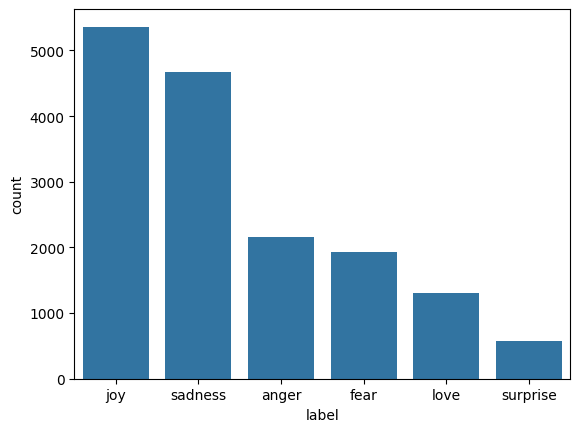

In [10]:
sns.countplot(x='label',data=df_train, order=df_train['label'].value_counts().index)

<Axes: xlabel='label', ylabel='count'>

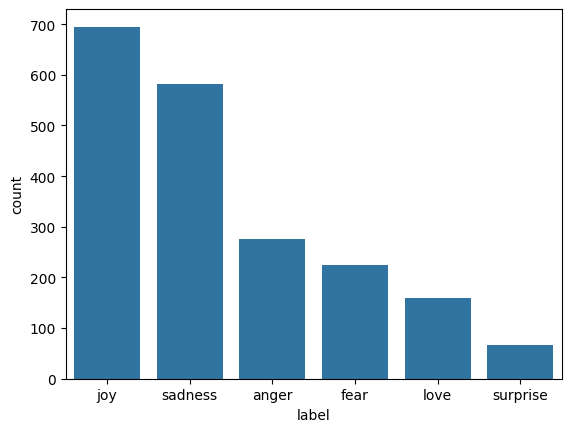

In [11]:
sns.countplot(x='label',data=df_test,order=df_test['label'].value_counts().index)

In [12]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_len=10000
tokenizer=Tokenizer(num_words=max_len,oov_token="<unk>")

In [13]:
tokenizer.fit_on_texts(df_train['text'])

In [14]:
train_seq=tokenizer.texts_to_sequences(df_train['text'])
test_seq=tokenizer.texts_to_sequences(df_test['text'])

In [15]:
train_seq[0]

[2, 139, 3, 679]

In [16]:
max_len=50
padded_train_seq=pad_sequences(train_seq,maxlen=max_len,padding='post',truncating='post')
padded_test_seq=pad_sequences(test_seq,maxlen=max_len,padding='post',truncating='post')


In [17]:
padded_train_seq[0]

array([  2, 139,   3, 679,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0], dtype=int32)

In [18]:
train_labels=np.array(train_labels)
test_labels=np.array(test_labels)
num_classes=len(np.unique(train_labels))
num_classes

6

In [19]:
train_labels

array([0, 0, 3, ..., 1, 3, 0])

In [20]:
test_labels

array([0, 0, 0, ..., 1, 1, 4])

In [21]:
print("Vocabulary Size:",len(tokenizer.word_index))
print("Maximum Sequence Length:",max_len)
print("Number of Classes:",num_classes)

Vocabulary Size: 15213
Maximum Sequence Length: 50
Number of Classes: 6


In [22]:
from sklearn.utils import class_weight

class_weights=class_weight.compute_class_weight(class_weight='balanced',classes=np.unique(train_labels),y=train_labels)

In [23]:
class_weight_dict=dict(enumerate(class_weights))

In [24]:
class_weight_dict

{0: np.float64(0.5715102157451064),
 1: np.float64(0.49732686808404825),
 2: np.float64(2.044989775051125),
 3: np.float64(1.2351397251814111),
 4: np.float64(1.3766993632765445),
 5: np.float64(4.662004662004662)}

In [25]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping=EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)
model_checkpoint=ModelCheckpoint('best_model.h5',monitor='val_loss',save_best_only=True)

In [26]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, SimpleRNN, GRU, Bidirectional



In [27]:
rnn_model = Sequential([
    Embedding(
        input_dim=len(tokenizer.word_index) + 1,
        output_dim=128,
        input_length=max_len
    ),
    SimpleRNN(128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(64),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])

rnn_model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

history = rnn_model.fit(
    padded_train_seq,
    train_labels,
    validation_data=(padded_test_seq, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping, model_checkpoint]
)

Epoch 1/20
499/500 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.1645 - loss: 2.0645

500/500 ━━━━━━━━━━━━━━━━━━━━ 32s 57ms/step - accuracy: 0.1635 - loss: 2.0351 - val_accuracy: 0.1240 - val_loss: 1.8079
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 30s 59ms/step - accuracy: 0.1416 - loss: 1.8833 - val_accuracy: 0.0350 - val_loss: 1.8192
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.1458 - loss: 1.8484

500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 60ms/step - accuracy: 0.1472 - loss: 1.8231 - val_accuracy: 0.2365 - val_loss: 1.7928
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.1383 - loss: 1.8140

500/500 ━━━━━━━━━━━━━━━━━━━━ 29s 57ms/step - accuracy: 0.1341 - loss: 1.8078 - val_accuracy: 0.1395 - val_loss: 1.7619
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 57ms/step - accuracy: 0.1392 - loss: 1.8040 - val_accuracy: 0.0400 - val_loss: 1.8093
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 57ms/step - accuracy: 0.1449 - loss: 1.8002 - val_accuracy: 0.0845 - val_loss: 1.7762
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.1485 - loss: 1.8012

500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 58ms/step - accuracy: 0.1410 - loss: 1.8013 - val_accuracy: 0.2610 - val_loss: 1.7486
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 28s 56ms/step - accuracy: 0.1369 - loss: 1.7994 - val_accuracy: 0.0955 - val_loss: 1.8137
Epoch 9/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 28s 57ms/step - accuracy: 0.1341 - loss: 1.8013 - val_accuracy: 0.0370 - val_loss: 1.8154
Epoch 10/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 29s 58ms/step - accuracy: 0.1424 - loss: 1.8028 - val_accuracy: 0.2525 - val_loss: 1.7670


In [28]:
rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_seq, test_labels)
print(f"RNN Test Loss: {rnn_loss:.4f}, RNN Test Accuracy: {rnn_accuracy:.4f}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.2610 - loss: 1.7486
RNN Test Loss: 1.7486, RNN Test Accuracy: 0.2610


In [29]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

lstm_early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

lstm_model_checkpoint = ModelCheckpoint(
    'lstm_best_model.h5',
    monitor='val_loss',
    save_best_only=True
)

lstm_model = Sequential([
    Embedding(
        input_dim=len(tokenizer.word_index) + 1,
        output_dim=128,
        input_length=max_len,
        mask_zero=True
    ),
    LSTM(128, return_sequences=True),
    Dropout(0.3),
    LSTM(64),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

lstm_model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

lstm_history = lstm_model.fit(
    padded_train_seq,
    train_labels,
    validation_data=(padded_test_seq, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[lstm_early_stopping, lstm_model_checkpoint]
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_seq, test_labels)
print(f"LSTM Test Loss: {lstm_loss:.4f}, LSTM Test Accuracy: {lstm_accuracy:.4f}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - accuracy: 0.3795 - loss: 1.5214

500/500 ━━━━━━━━━━━━━━━━━━━━ 84s 159ms/step - accuracy: 0.5520 - loss: 1.1467 - val_accuracy: 0.8655 - val_loss: 0.4487
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.8930 - loss: 0.3248

500/500 ━━━━━━━━━━━━━━━━━━━━ 76s 152ms/step - accuracy: 0.8963 - loss: 0.3041 - val_accuracy: 0.9135 - val_loss: 0.2759
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.9331 - loss: 0.1838

500/500 ━━━━━━━━━━━━━━━━━━━━ 77s 155ms/step - accuracy: 0.9342 - loss: 0.1833 - val_accuracy: 0.9155 - val_loss: 0.2565
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step - accuracy: 0.9565 - loss: 0.1110

500/500 ━━━━━━━━━━━━━━━━━━━━ 78s 155ms/step - accuracy: 0.9540 - loss: 0.1208 - val_accuracy: 0.9180 - val_loss: 0.2340
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 77s 154ms/step - accuracy: 0.9666 - loss: 0.0855 - val_accuracy: 0.9190 - val_loss: 0.2562
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 78s 155ms/step - accuracy: 0.9749 - loss: 0.0672 - val_accuracy: 0.9160 - val_loss: 0.2578
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 78s 155ms/step - accuracy: 0.9767 - loss: 0.0592 - val_accuracy: 0.9165 - val_loss: 0.3024
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.9180 - loss: 0.2340
LSTM Test Loss: 0.2340, LSTM Test Accuracy: 0.9180


In [30]:
gru_early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

gru_model_checkpoint = ModelCheckpoint(
    'gru_best_model.h5',
    monitor='val_loss',
    save_best_only=True
)

gru_model = Sequential([
    Embedding(
        input_dim=len(tokenizer.word_index) + 1,
        output_dim=128,
        input_length=max_len,
        mask_zero=True
    ),
    GRU(128, return_sequences=True),
    Dropout(0.3),
    GRU(64),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

gru_model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

gru_history = gru_model.fit(
    padded_train_seq,
    train_labels,
    validation_data=(padded_test_seq, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[gru_early_stopping, gru_model_checkpoint]
)

gru_loss, gru_accuracy = gru_model.evaluate(
    padded_test_seq,
    test_labels
)

print(f"GRU Test Loss: {gru_loss:.4f}, GRU Test Accuracy: {gru_accuracy:.4f}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.2949 - loss: 1.5379

500/500 ━━━━━━━━━━━━━━━━━━━━ 69s 132ms/step - accuracy: 0.5348 - loss: 1.0710 - val_accuracy: 0.9050 - val_loss: 0.2955
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step - accuracy: 0.9213 - loss: 0.2183

500/500 ━━━━━━━━━━━━━━━━━━━━ 66s 131ms/step - accuracy: 0.9260 - loss: 0.2060 - val_accuracy: 0.9265 - val_loss: 0.2167
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step - accuracy: 0.9475 - loss: 0.1274

500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 131ms/step - accuracy: 0.9467 - loss: 0.1336 - val_accuracy: 0.9205 - val_loss: 0.1929
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 85s 137ms/step - accuracy: 0.9611 - loss: 0.0981 - val_accuracy: 0.9180 - val_loss: 0.2278
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 78s 129ms/step - accuracy: 0.9696 - loss: 0.0803 - val_accuracy: 0.9260 - val_loss: 0.2241
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 65s 131ms/step - accuracy: 0.9761 - loss: 0.0638 - val_accuracy: 0.9200 - val_loss: 0.2633
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.9205 - loss: 0.1929
GRU Test Loss: 0.1929, GRU Test Accuracy: 0.9205


In [31]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Callbacks for Bidirectional GRU
bigru_early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

bigru_model_checkpoint = ModelCheckpoint(
    'bigru_best_model.h5',
    monitor='val_loss',
    save_best_only=True
)

# Model Definition
bigru_model = Sequential([
    Embedding(
        input_dim=len(tokenizer.word_index) + 1,
        output_dim=128,
        input_length=max_len,
        mask_zero=True
    ),
    Bidirectional(GRU(128, return_sequences=True)),
    Dropout(0.3),
    Bidirectional(GRU(64)),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')
])

# Compile
bigru_model.compile(
    loss='sparse_categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

# Train
bigru_history = bigru_model.fit(
    padded_train_seq,
    train_labels,
    validation_data=(padded_test_seq, test_labels),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[bigru_early_stopping, bigru_model_checkpoint]
)

# Evaluate
bigru_loss, bigru_accuracy = bigru_model.evaluate(
    padded_test_seq,
    test_labels
)

print(f"Bidirectional GRU Test Loss: {bigru_loss:.4f}, Bidirectional GRU Test Accuracy: {bigru_accuracy:.4f}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step - accuracy: 0.3592 - loss: 1.4503

500/500 ━━━━━━━━━━━━━━━━━━━━ 160s 306ms/step - accuracy: 0.6165 - loss: 0.9497 - val_accuracy: 0.8970 - val_loss: 0.3024
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 292ms/step - accuracy: 0.9287 - loss: 0.2062

500/500 ━━━━━━━━━━━━━━━━━━━━ 198s 299ms/step - accuracy: 0.9306 - loss: 0.1859 - val_accuracy: 0.9195 - val_loss: 0.2136
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 160s 321ms/step - accuracy: 0.9544 - loss: 0.1142 - val_accuracy: 0.9155 - val_loss: 0.2361
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 134s 268ms/step - accuracy: 0.9660 - loss: 0.0810 - val_accuracy: 0.9200 - val_loss: 0.2269
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 133s 266ms/step - accuracy: 0.9743 - loss: 0.0690 - val_accuracy: 0.9165 - val_loss: 0.2917
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.9195 - loss: 0.2136
Bidirectional GRU Test Loss: 0.2136, Bidirectional GRU Test Accuracy: 0.9195


63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step


<Axes: >

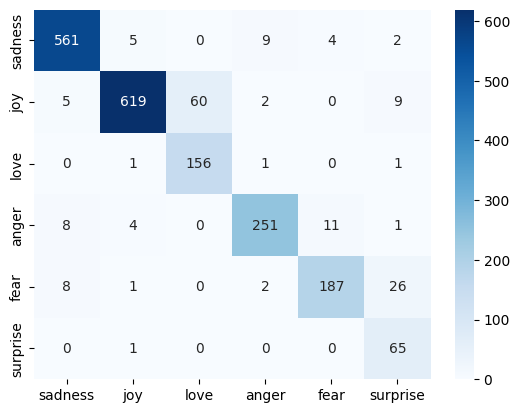

In [32]:
from sklearn.metrics import confusion_matrix

BiGRU_predictions = np.argmax(bigru_model.predict(padded_test_seq),axis=1)

sns.heatmap(confusion_matrix(test_labels, BiGRU_predictions),annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)

In [33]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_predictions = np.argmax(bigru_model.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step
Text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: surprise
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


In [34]:

import os
import pickle

model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True)
bigru_model.save(os.path.join(model_dir, 'BiGRU_Modle.keras'))

#Save the tokenizer model
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
  pickle.dump(tokenizer, file)